# 3. After context engineering

## Summary

On the same original 128-invoice holdout, balanced SAP RPT context finds **16 of 22** fraud cases with **12 false alarms**. The matched random 128-row context finds **10 of 22** with **3 false alarms**. Fraud F1 changes from **0.571 to 0.640**; late-payment F1 changes from **0.511 to 0.505**. XGBoost is shown as an unchanged reference, trained on 1,024 rows. The [before notebook](01_before_context_engineering.ipynb) covers the original baseline, and the [in-context notebook](02_in_context_changes.ipynb) shows the selection and request checks.

## Context and methods

The source labels and final 128 test invoice IDs are identical throughout. The original saved SAP RPT benchmark used 1,024 labeled examples and both target columns in its request. The controlled comparison gives SAP RPT either random or class-balanced 128-row context (seed 11), one target per request, with fixed model weights. Only the selected examples change between these matched conditions. XGBoost retains its original 1,024-row training result; its cross-model comparison is descriptive because the labeled-data budgets differ. This notebook reads saved predictions and makes no live SAP request.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
FIONEER_BLUE = '#0F37FF'
FIONEER_NAVY = '#353C54'
FIONEER_LIGHT_BLUE = '#CFDEFF'
FIONEER_YELLOW = '#FFD53C'
ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / 'archive/synthetic_invoice_experiments/published_baseline/payment_behavior.csv').exists())
sys.path[:0] = [str(ROOT / 'src'), str(ROOT / 'scripts')]
from context_engineering import assert_no_leakage, select_context
from run_context_benchmark import request_for, metric_row
source_path = ROOT / 'archive/synthetic_invoice_experiments/published_baseline/payment_behavior.csv'
source = pd.read_csv(source_path)
pool, holdout = source.iloc[:1024].copy(), source.iloc[1024:].copy()
targets = ('paid_late', 'is_fraud')
seed, budget = 11, 128
assert len(source) == 1152 and len(pool) == 1024 and len(holdout) == 128
assert int(holdout.is_fraud.sum()) == 22 and int(holdout.paid_late.sum()) == 51
assert source.invoice_id.is_unique and not source.isna().any().any()
assert_no_leakage(pool, holdout)


## Results
Recompute SAP RPT counts from saved predictions. A missing condition stays missing until a live request succeeds.

In [2]:
saved = pd.read_csv(ROOT / 'data/synthetic_invoices/rpt16_results.csv')
new = pd.read_csv(ROOT / 'data/original_context_comparison/results.csv')
new = new[new.model == 'SAP-RPT'].copy()
predictions = pd.read_csv(ROOT / 'data/original_context_comparison/predictions.csv')
assert set(zip(new.strategy, new.target)) == {
    (strategy, target) for strategy in ('random', 'balanced') for target in targets
}
rows = []
for target in targets:
    assert saved.invoice_id.tolist() == holdout.invoice_id.tolist()
    assert saved[f'actual_{target}'].tolist() == holdout[target].tolist()
    rows.append({'stage': 'first benchmark (1024 rows)', 'target': target,
                 **metric_row(holdout[target].to_numpy(), saved[f'predicted_{target}'].to_numpy())})
for result in new.itertuples():
    sample = predictions[predictions.run_id == result.run_id].set_index('invoice_id').loc[holdout.invoice_id]
    assert sample.actual.tolist() == holdout[result.target].tolist()
    checked = metric_row(sample.actual.to_numpy(), sample.predicted.to_numpy())
    assert checked['true_positives'] == result.true_positives
    assert checked['false_positives'] == result.false_positives
    rows.append({'stage': f'{result.strategy} (128 rows)', 'target': result.target,
                 **checked})
comparison = pd.DataFrame(rows)
display(comparison[['stage', 'target', 'true_positives', 'false_positives',
                    'precision', 'recall', 'f1', 'accuracy']].round(3))


,stage,target,true_positives,false_positives,precision,recall,f1,accuracy
0,first benchmark (1024 rows),paid_late,34,20,0.630,0.667,0.648,0.711
1,first benchmark (1024 rows),is_fraud,10,5,0.667,0.455,0.541,0.867
2,random (128 rows),paid_late,23,16,0.590,0.451,0.511,0.656
3,random (128 rows),is_fraud,10,3,0.769,0.455,0.571,0.883
4,balanced (128 rows),paid_late,26,26,0.500,0.510,0.505,0.602
5,balanced (128 rows),is_fraud,16,12,0.571,0.727,0.640,0.859


### What improved for SAP RPT?
This is the controlled in-context learning comparison: only example selection changes between random and balanced contexts. The table reports percentage-point changes for recall, precision, and F1, plus invoice counts. Higher recall comes with more false alarms.

,Random 128,Balanced 128,Change
Measure,,,
Fraud cases found / 22,10.000,16.000,6.000
False alarms / 106,3.000,12.000,9.000
Fraud recall,0.455,0.727,0.273
Fraud precision,0.769,0.571,-0.198
Fraud F1,0.571,0.640,0.069


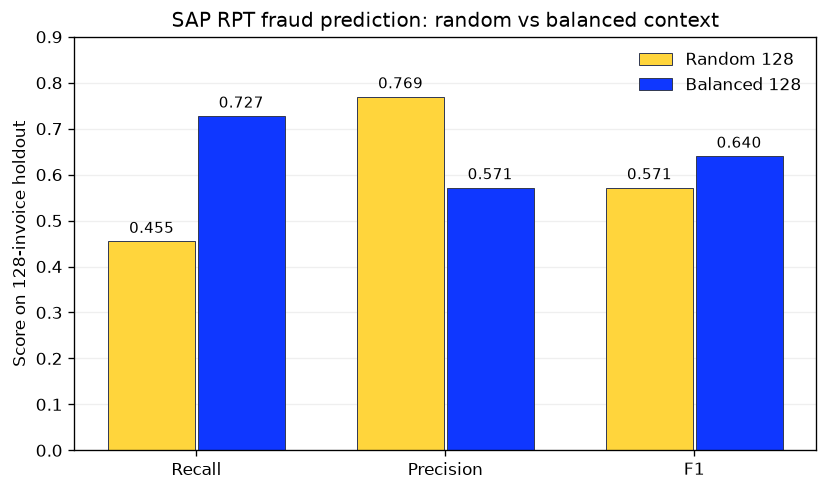

In [3]:
rpt_fraud = comparison[comparison.target == 'is_fraud'].set_index('stage')
before = rpt_fraud.loc['random (128 rows)']
after = rpt_fraud.loc['balanced (128 rows)']
assert (int(before.true_positives), int(before.false_positives)) == (10, 3)
assert (int(after.true_positives), int(after.false_positives)) == (16, 12)
improvement = pd.DataFrame({
    'Measure': ['Fraud cases found / 22', 'False alarms / 106', 'Fraud recall',
                'Fraud precision', 'Fraud F1'],
    'Random 128': [before.true_positives, before.false_positives,
                   before.recall, before.precision, before.f1],
    'Balanced 128': [after.true_positives, after.false_positives,
                     after.recall, after.precision, after.f1],
})
improvement['Change'] = improvement['Balanced 128'] - improvement['Random 128']
display(improvement.set_index('Measure').round(3))
fig, ax = plt.subplots(figsize=(7, 4.2))
positions = np.arange(3)
metrics = ['recall', 'precision', 'f1']
for offset, condition, row, color in [(-.18, 'Random 128', before, FIONEER_YELLOW),
                                       (.18, 'Balanced 128', after, FIONEER_BLUE)]:
    values = [float(row[metric]) for metric in metrics]
    bars = ax.bar(positions + offset, values, width=.35, color=color,
                  edgecolor=FIONEER_NAVY, linewidth=.6, label=condition)
    ax.bar_label(bars, labels=[f'{value:.3f}' for value in values], padding=3, fontsize=9)
ax.set_xticks(positions, ['Recall', 'Precision', 'F1'])
ax.set_ylim(0, 0.9)
ax.set_ylabel('Score on 128-invoice holdout')
ax.set_title('SAP RPT fraud prediction: random vs balanced context')
ax.legend(frameon=False)
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(ROOT / 'reports/figures/original22_rpt_fraud_random_vs_balanced.png',
            dpi=200, bbox_inches='tight')
plt.show()


### Fraud detections and false alarms
The first 1,024-row SAP RPT benchmark provides historical context. Compare the two 128-row conditions to assess selection while holding the context budget fixed. All bars use the same test set with 22 fraud and 106 nonfraud invoices.

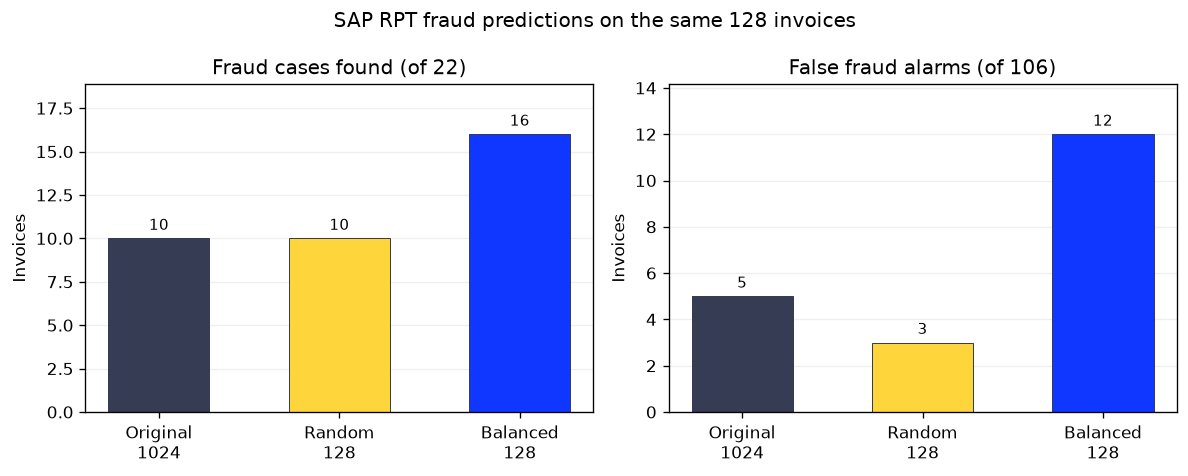

In [4]:
fraud = comparison[comparison.target == 'is_fraud'].set_index('stage')
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
stages = ['first benchmark (1024 rows)', 'random (128 rows)', 'balanced (128 rows)']
for ax, column, title in zip(axes, ['true_positives', 'false_positives'],
                             ['Fraud cases found (of 22)', 'False fraud alarms (of 106)']):
    values = [int(fraud.loc[stage, column]) for stage in stages]
    bars = ax.bar(range(3), values, width=0.56,
                  color=[FIONEER_NAVY, FIONEER_YELLOW, FIONEER_BLUE],
                  edgecolor=FIONEER_NAVY, linewidth=.6)
    ax.bar_label(bars, labels=[str(value) for value in values], padding=3, fontsize=9)
    ax.set_xticks(range(3), ['Original\n1024', 'Random\n128', 'Balanced\n128'])
    ax.set_ylim(0, max(values) * 1.18)
    ax.set_title(title)
    ax.set_ylabel('Invoices')
    ax.grid(axis='y', alpha=.2)
    ax.set_axisbelow(True)
fig.suptitle('SAP RPT fraud predictions on the same 128 invoices')
fig.tight_layout()
fig.savefig(ROOT / 'reports/figures/original22_rpt_fraud_detections_false_alarms.png',
            dpi=200, bbox_inches='tight')
plt.show()


### Reference: balanced SAP RPT and unchanged XGBoost
Both predictions use the same original 128 test invoice IDs and labels. XGBoost trained on all 1,024 eligible rows in the first benchmark; SAP RPT used 128 balanced in-context examples. This table locates the after-context SAP RPT result against the XGBoost result. Different example budgets and modeling procedures prevent a controlled model ranking or an estimate of the context-selection effect from this cross-model comparison.

In [5]:
xgb_saved = pd.read_csv(ROOT / 'data/synthetic_invoices/xgboost_results.csv')
reference_rows = []
for target in targets:
    assert xgb_saved.invoice_id.tolist() == holdout.invoice_id.tolist()
    assert xgb_saved[f'actual_{target}'].tolist() == holdout[target].tolist()
    xgb = metric_row(holdout[target].to_numpy(), xgb_saved[f'predicted_{target}'].to_numpy())
    rpt = comparison[(comparison.target == target) &
                     (comparison.stage == 'balanced (128 rows)')].iloc[0]
    for model, labeled_rows, metrics in [
        ('XGBoost', 1024, xgb),
        ('SAP RPT balanced', 128, rpt),
    ]:
        reference_rows.append({
            'Target': target, 'Condition': model, 'Labeled rows': labeled_rows,
            'Cases found': f"{int(metrics['true_positives'])}/{int(holdout[target].sum())}",
            'False alarms': int(metrics['false_positives']),
            'Precision': float(metrics['precision']),
            'Recall': float(metrics['recall']),
            'F1': float(metrics['f1']),
        })
reference = pd.DataFrame(reference_rows)
display(reference.round(3))


,Target,Condition,Labeled rows,Cases found,False alarms,Precision,Recall,F1
0,paid_late,XGBoost,1024,32/51,25,0.561,0.627,0.593
1,paid_late,SAP RPT balanced,128,26/51,26,0.500,0.510,0.505
2,is_fraud,XGBoost,1024,15/22,9,0.625,0.682,0.652
3,is_fraud,SAP RPT balanced,128,16/22,12,0.571,0.727,0.640


### Visual reference: XGBoost versus balanced-context SAP RPT
The same 128 holdout invoices are scored in both conditions. The F1 panel covers both targets; the fraud panel shows the detection and false-alarm tradeoff. XGBoost trained on 1,024 rows, while SAP RPT used 128 selected context rows, so these bars are a descriptive reference rather than a controlled model ranking.

Saved /Users/marla/Documents/GitHub/tfm/reports/figures/xgboost_vs_context_enhanced_rpt.png


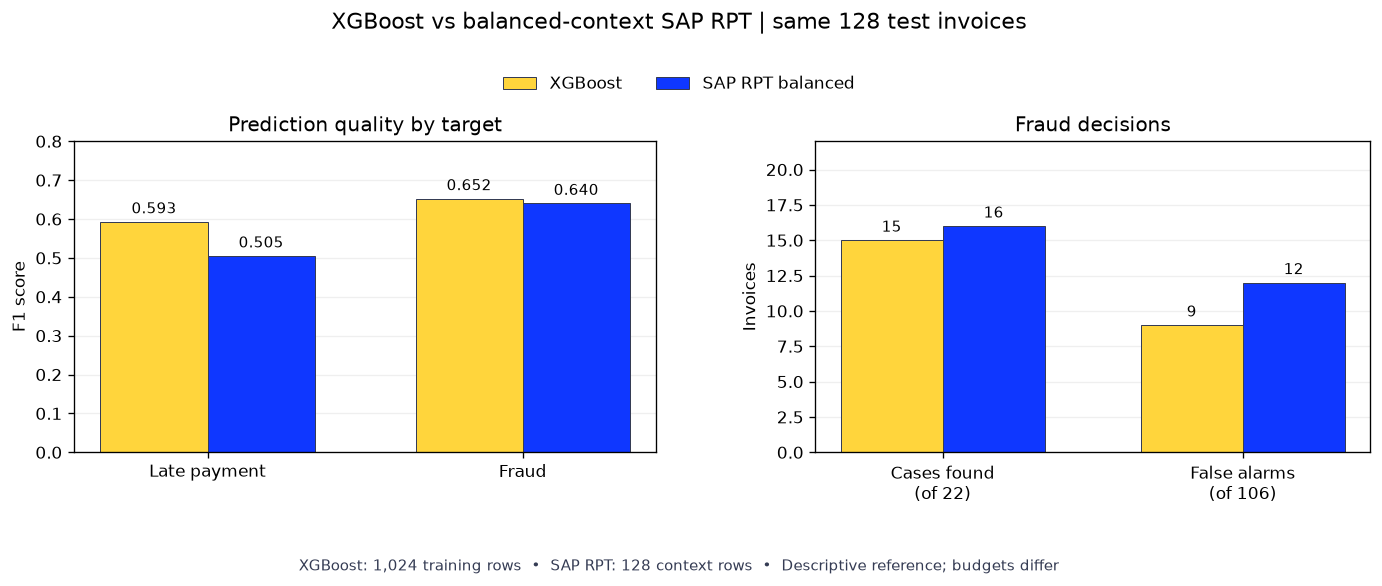

In [6]:
labels = ['XGBoost', 'SAP RPT balanced']
colors = [FIONEER_YELLOW, FIONEER_BLUE]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={'width_ratios': [1.05, 1]})
positions = np.arange(2)
width = 0.34
for index, (condition, color) in enumerate(zip(labels, colors)):
    subset = reference.set_index(['Target', 'Condition'])
    scores = [float(subset.loc[(target, condition), 'F1']) for target in ('paid_late', 'is_fraud')]
    bars = axes[0].bar(positions + (index - .5) * width, scores, width,
                       color=color, edgecolor=FIONEER_NAVY, linewidth=.6, label=condition)
    axes[0].bar_label(bars, labels=[f'{score:.3f}' for score in scores], padding=3, fontsize=9)
    fraud = subset.loc[('is_fraud', condition)]
    counts = [int(fraud['Cases found'].split('/')[0]), int(fraud['False alarms'])]
    bars = axes[1].bar(positions + (index - .5) * width, counts, width,
                       color=color, edgecolor=FIONEER_NAVY, linewidth=.6)
    axes[1].bar_label(bars, labels=[str(count) for count in counts], padding=3, fontsize=9)
axes[0].set_xticks(positions, ['Late payment', 'Fraud'])
axes[0].set_ylim(0, .8)
axes[0].set_ylabel('F1 score')
axes[0].set_title('Prediction quality by target')
axes[1].set_xticks(positions, ['Cases found\n(of 22)', 'False alarms\n(of 106)'])
axes[1].set_ylim(0, 22)
axes[1].set_ylabel('Invoices')
axes[1].set_title('Fraud decisions')
for ax in axes:
    ax.grid(axis='y', alpha=.2)
    ax.set_axisbelow(True)
fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center',
           bbox_to_anchor=(.5, .91), ncol=2, frameon=False)
fig.suptitle('XGBoost vs balanced-context SAP RPT | same 128 test invoices',
             fontsize=13, y=.995)
fig.text(.5, .025,
         'XGBoost: 1,024 training rows  •  SAP RPT: 128 context rows  •  Descriptive reference; budgets differ',
         ha='center', fontsize=9, color=FIONEER_NAVY)
fig.subplots_adjust(top=.77, bottom=.23, left=.08, right=.98, wspace=.28)
figure_path = ROOT / 'reports/figures/xgboost_vs_context_enhanced_rpt.png'
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=200, bbox_inches='tight')
plt.show()
print(f'Saved {figure_path}')


### Fraud ROC AUC and average precision

ROC AUC measures ranking across thresholds; average precision summarizes the precision–recall curve. The separate SAP RPT `top_k=2` score call used the **same balanced 128-row fraud context and seed 11**. The checks below verify that its top labels match all 128 saved after-context predictions. This permits a descriptive ranking comparison with XGBoost on the same holdout; it is not a matched comparison of training budgets. There are no corresponding positive-class scores for the original before-context SAP RPT run.

                       Model  ROC AUC  Average precision
                     XGBoost    0.804              0.587
SAP RPT after context change    0.872              0.665

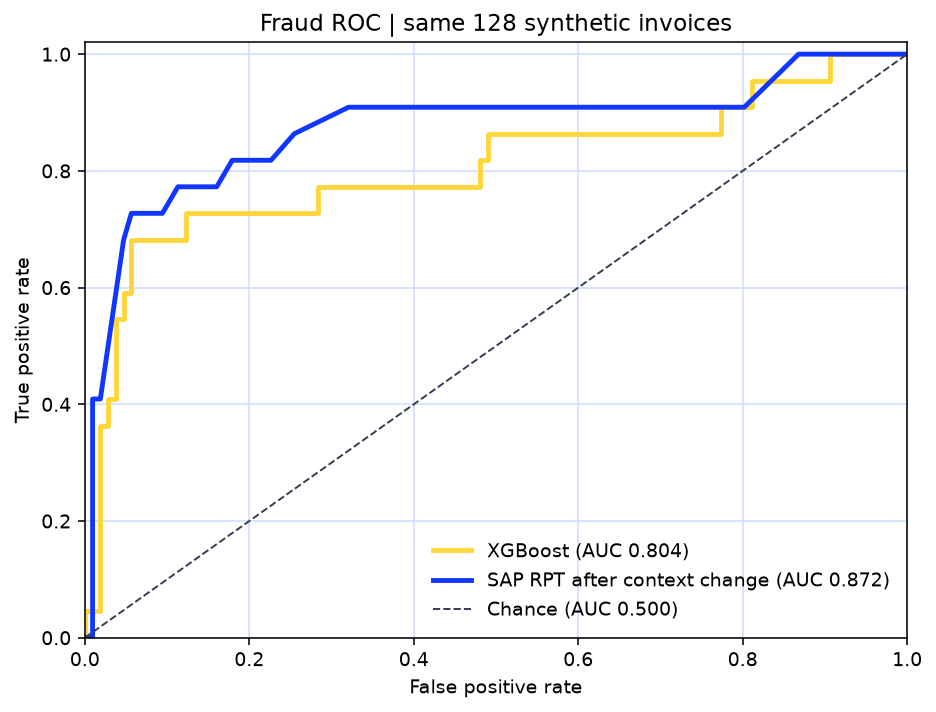

In [4]:
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
import sys
sys.path[:0] = [str(ROOT / 'src'), str(ROOT / 'scripts')]
from context_engineering import select_context
from run_rpt_context_mix import select_rows

pool = source.iloc[:1024]
original_context, _ = select_context(pool, 'is_fraud', holdout.iloc[:1],
                                     'balanced', 128, 11)
scored_context = select_rows(pool, 128, 0.50, 11)
assert original_context.invoice_id.tolist() == scored_context.invoice_id.tolist()

scored = pd.read_csv(ROOT / 'data/rpt_context_mix/holdout_predictions.csv')
scored = scored[scored.run_id == 'holdout|128|0.50|11']
assert len(scored) == 128 and scored.invoice_id.is_unique
scored = scored.set_index('invoice_id').loc[holdout.invoice_id]
saved_rpt = predictions[predictions.run_id == 'original22|balanced|is_fraud|11|SAP-RPT']
saved_rpt = saved_rpt.set_index('invoice_id').loc[holdout.invoice_id]
assert scored.actual.to_numpy().tolist() == holdout.is_fraud.tolist()
assert scored.top_label.to_numpy().tolist() == saved_rpt.predicted.tolist()
assert np.allclose(scored.score_positive + scored.score_negative, 1)

actual_fraud = holdout.is_fraud.to_numpy()
fraud_scores = {
    'XGBoost': xgb_saved.probability_is_fraud.to_numpy(),
    'SAP RPT after context change': scored.score_positive.to_numpy(),
}
ranking = pd.DataFrame([
    {'Model': model, 'ROC AUC': roc_auc_score(actual_fraud, scores),
     'Average precision': average_precision_score(actual_fraud, scores)}
    for model, scores in fraud_scores.items()
])
display(ranking.round(3))

fig, ax = plt.subplots(figsize=(6.8, 5.2))
for model, color in [('XGBoost', FIONEER_YELLOW), ('SAP RPT after context change', FIONEER_BLUE)]:
    fpr, tpr, _ = roc_curve(actual_fraud, fraud_scores[model])
    auc = roc_auc_score(actual_fraud, fraud_scores[model])
    ax.plot(fpr, tpr, color=color, linewidth=2.5, label=f'{model} (AUC {auc:.3f})')
ax.plot([0, 1], [0, 1], linestyle='--', color=FIONEER_NAVY,
        linewidth=1, label='Chance (AUC 0.500)')
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel='False positive rate',
       ylabel='True positive rate', title='Fraud ROC | same 128 synthetic invoices')
ax.grid(color=FIONEER_LIGHT_BLUE, linewidth=.8)
ax.legend(loc='lower right', frameon=False)
plt.tight_layout()
figure_path = ROOT / 'reports/figures/xgboost_vs_context_enhanced_rpt_roc.png'
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=200, bbox_inches='tight')
plt.show()

## Takeaways

At the matched 128-row budget, balanced SAP RPT finds six more fraud cases than random context (**16 vs 10 of 22**) but raises false alarms from **3 to 12**. Fraud F1 rises from **0.571 to 0.640**; late-payment F1 does not improve (**0.511 to 0.505**).

Against unchanged XGBoost, balanced SAP RPT finds **16 vs 15** fraud cases with **12 vs 9** false alarms; F1 is **0.640 vs 0.652**. In the separate score run, fraud ROC AUC is **0.872 vs 0.804** and average precision is **0.665 vs 0.587** for SAP RPT and XGBoost, respectively. Ranking quality and the chosen yes/no decisions answer different questions. These cross-model numbers use different labeled-data budgets, one seed, one synthetic holdout, and do not establish a general model ranking.

A later validation-selected context mix and threshold setting did not improve holdout F1; its saved protocol and predictions remain in `data/rpt_context_mix/`.